In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    VotingClassifier
)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

sns.set_style("whitegrid")

# Task 1: Load and Explore the Dataset

Before building models, we need to understand the data.

### 1\. Load the dataset

Use scikit-learn to load the Breast Cancer Wisconsin dataset:

In [2]:
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

X.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


I am observing that all the data is numerical, but not on the same scale so it will likely need to be normalized for training.

In [3]:
y.tail()
y.value_counts()

target
1    357
0    212
Name: count, dtype: int64

I am noticiing that most of these samples are benign.


### 2\. Explore the dataset


In [4]:
print(X.shape)
print(X.columns.to_list())
X.info()
sum(X.isna().sum())

(569, 30)
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-n

0

The first thing I am noticing is that there are no Nans. Also we have a fairly large sample with 569 rows.

### Questions

Answer the following in a Markdown cell:

1. How many observations are in the dataset?
2. How many predictor variables are available?
3. Are the features numerical or categorical?
4. Are there any missing values?
5. How many observations belong to each target class?
6. Is the target balanced or imbalanced?

### Answers
1. There are 569 observations in the dataset.
2. There are 30 available variables.
3. All the features are numerical.
4. There are no missing values.
5. There are 369 1's (benign) sample and 212 0's (Malignent).
6. The target is close to balanced so it shouldn't need more balancing.

# Task 2: Understand the Target Variable

The dataset provides numerical target values.

Use:

In [5]:
print(data.target_names)

['malignant' 'benign']


In [6]:
y.value_counts()

target
1    357
0    212
Name: count, dtype: int64

Malignant:  212
Benign:  357


<Axes: xlabel='target'>

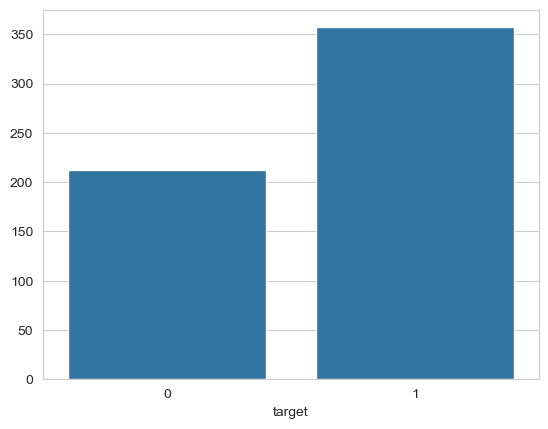

In [7]:
print("Malignant: ", y.value_counts()[0])
print("Benign: ", y.value_counts()[1])
sns.barplot(x=y.value_counts().index, y=y.value_counts().values)

### Questions

1. What does class `0` represent?
2. What does class `1` represent?
3. Which class has more observations?
4. Why should we consider class balance when evaluating a classification model?

### Answers
1. Class 0 represents malignant samples.
2. Class 1 represents benign samples.
3. There are more bening samples.
4. If the classes are unbalanced, the model will be strongly biased to predict the majority class. In this instance I don't think we should balance the classes. The split is roughly 60/40 so there will be little effect on the model.

# Task 3: Split the Data

Split the data into training and test sets.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


### Questions

Report:

- Number of training observations
- Number of test observations
- Number of features

Explain why we use:

```
stratify=y
```

when creating the train/test split.

---

### Answers
1. 455
2. 114
3. 30
4. The random sampling that occurs in splitting the data could imbalance the training data towards one target. We use stratify=y to keep the balance in the train and test sets the same as the overall data.

# Task 4: Build a Single Decision Tree

Before using bagging, we need a baseline model.

Train a single decision tree:

In [9]:
tree = DecisionTreeClassifier(
    random_state=42
)

tree.fit(X_train, y_train)
y_pred_tree = tree.predict(X_test)

tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

print("Accuracy:", tree_accuracy)

tree_f1 = f1_score(
    y_test,
    y_pred_tree
)

print("F1:", tree_f1)

print(
    classification_report(
        y_test,
        y_pred_tree,
        target_names=data.target_names
    )
)

Accuracy: 0.9122807017543859
F1: 0.9285714285714286
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



In [10]:
log = LogisticRegression(
    random_state=42
)

log.fit(X_train, y_train)
y_pred_log = log.predict(X_test)

log_accuracy = accuracy_score(
    y_test,
    y_pred_log
)

print("Accuracy:", log_accuracy)

log_f1 = f1_score(
    y_test,
    y_pred_log
)

print("F1:", log_f1)

print(
    classification_report(
        y_test,
        y_pred_log,
        target_names=data.target_names
    )
)


Accuracy: 0.9649122807017544
F1: 0.9726027397260274
              precision    recall  f1-score   support

   malignant       0.97      0.93      0.95        42
      benign       0.96      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



c:\Users\jehow\anaconda3\envs\datascience\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [11]:
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(X_train, y_train)
y_pred_knn = knn.predict(X_test)

knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn
)

print("Accuracy:", knn_accuracy)

knn_f1 = f1_score(
    y_test,
    y_pred_knn
)

print("F1:", knn_f1)

print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=data.target_names
    )
)

Accuracy: 0.9122807017543859
F1: 0.9295774647887324
              precision    recall  f1-score   support

   malignant       0.86      0.90      0.88        42
      benign       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114



c:\Users\jehow\anaconda3\envs\datascience\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\jehow\anaconda3\envs\datascience\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\jehow\anaconda3\envs\datascience\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\jehow\anaconda3\envs\datascience\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\jehow\anaconda3\envs\datascience\Lib\

### Questions

1. What accuracy did the decision tree achieve?
2. What F1 score did it achieve?
3. Why is it useful to establish a baseline before building an ensemble?
4. What does it mean for a model to have high variance?


### Answers
1. The decision tree achieved an accuracy of 91.2%.
2. The decision tree achieved an F1 score of 92.8%.
3. The baseline provides us the ability to compare models in order to test if the added complexity is effective.
4. A model with high variance will have an accuracy score that varies alot.

# Task 5: Understand Bootstrapping

Before using a bagging model, let's create bootstrap samples manually.

Consider this simple dataset:



In [12]:
observations = np.array([
    "A", "B", "C", "D", "E"
])

Create a bootstrap sample:

In [13]:
bootstrap_sample = np.random.choice(
    observations,
    size=len(observations),
    replace=True
)

print(bootstrap_sample)

['E' 'E' 'B' 'A' 'C']


### Questions

Observe the results and answer:

1. Does every observation appear in every bootstrap sample?
2. Can an observation appear more than once?
3. Does each bootstrap sample contain five observations?
4. What does `replace=True` mean?
5. Why are the bootstrap samples different?

### Answers
1. No.
2. Yes.
3. Yes.
4. The replace=True allows for an element to be chosen multiple times.
5. The bootstrap samples are randomly chosen each time, so they are very rarely going to be the same.

# Task 6: Create Multiple Bootstrap Samples

Create five bootstrap samples:

In [14]:
for i in range(5):

    sample = np.random.choice(
        observations,
        size=len(observations),
        replace=True
    )

    print(
        f"Sample {i + 1}: {sample}"
    )

Sample 1: ['D' 'E' 'E' 'C' 'C']
Sample 2: ['E' 'C' 'D' 'B' 'C']
Sample 3: ['C' 'A' 'A' 'B' 'D']
Sample 4: ['D' 'A' 'D' 'D' 'D']
Sample 5: ['B' 'D' 'D' 'B' 'B']


### Questions

1. How are the samples different?
2. Do all samples contain the same observations?
3. Why might these differences be useful when training multiple models?

### Answers
1. None of them match each other.
2. They do not.
3. The different samples will allow the various models to hone-in on various trends within their own samples.

### Written Explanation

In a Markdown cell, explain:

> **How does sampling with replacement allow us to create different training datasets from the same original dataset?**

When using the replacement, we can end up with datasets that have duplicated instances, meaning no sample is exactly like the original dataset.

# Task 7: Bootstrap the Training Data

Now apply bootstrapping to the actual training data.

First combine the predictors and target:

In [15]:
train_data = X_train.copy()

train_data["target"] = y_train.values

# Create a bootstrap sample:

bootstrap_sample = train_data.sample(
    n=len(train_data),
    replace=True,
    random_state=42
)

# Inspect:

bootstrap_sample.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
68,9.029,17.33,58.79,250.5,0.10660,0.14130,0.31300,0.04375,0.2111,0.08046,...,22.65,65.50,324.7,0.1482,0.4365,1.25200,0.17500,0.4228,0.11750,1
378,13.660,15.15,88.27,580.6,0.08268,0.07548,0.04249,0.02471,0.1792,0.05897,...,19.64,97.96,657.0,0.1275,0.3104,0.25690,0.10540,0.3387,0.09638,1
326,14.110,12.88,90.03,616.5,0.09309,0.05306,0.01765,0.02733,0.1373,0.05700,...,18.00,98.40,749.9,0.1281,0.1109,0.05307,0.05890,0.2100,0.07083,1
502,12.540,16.32,81.25,476.3,0.11580,0.10850,0.05928,0.03279,0.1943,0.06612,...,21.40,86.67,552.0,0.1580,0.1751,0.18890,0.08411,0.3155,0.07538,1
195,12.910,16.33,82.53,516.4,0.07941,0.05366,0.03873,0.02377,0.1829,0.05667,...,22.00,90.81,600.6,0.1097,0.1506,0.17640,0.08235,0.3024,0.06949,1


### Investigate the Sample

Calculate the number of unique observations:

In [16]:
print(bootstrap_sample.index.nunique())

# Compare this with:

len(bootstrap_sample)

275


455

### Questions

1. Does the bootstrap sample have the same number of rows as the original training set?
2. Does it have the same number of unique observations?
3. Why are these numbers potentially different?
4. What does this tell you about sampling with replacement?

### Answer
1. Yes.
2. No.
3. These numbers are different because the bootstrap sample includes duplicate samples.
4. This tells me sampling produces a lot of duplicates.

# Task 8: Build a Bagging Classifier

Now let scikit-learn create bootstrap samples and train multiple models for us.

Create a bagging classifier using decision trees:

In [17]:
bagging_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)


# Train the model:


bagging_tree.fit(
    X_train,
    y_train
)


# Generate predictions:

y_pred_bagging = bagging_tree.predict(
    X_test
)


# Calculate accuracy and F1:


bagging_accuracy = accuracy_score(
    y_test,
    y_pred_bagging
)

bagging_f1 = f1_score(
    y_test,
    y_pred_bagging
)

print("Accuracy:", bagging_accuracy)
print("F1:", bagging_f1)

Accuracy: 0.9385964912280702
F1: 0.9517241379310345


Both of these scores are higher than they were for the single Decision Tree.

# Task 9: Compare One Tree vs. Bagging

Create a comparison table:

| Model | Accuracy | F1 |
| --- | --- | --- |
| Decision Tree | 91.2% | 0.93 |
| Bagging | 93.8% | 0.95 |

### Questions

1. Which model performed better?
2. Did bagging improve accuracy?
3. Did bagging improve F1?
4. Was the improvement large or small?
5. Why might combining multiple decision trees make predictions more stable?

### Answers
1. The bagging model performed better.
2. Yes.
3. Yes
4. The improvement was pretty large considering the single decision tree was fairly accurate. The bagging model reduced the inaccuracy by 20%.
5. Multiple decision trees can focus on different trends it finds within its own data. Also, large quantities are more stable than small quantities.

### Key Concept

Remember:

> **Bagging primarily helps reduce variance.**

It does not guarantee that every dataset will show a dramatic performance improvement.

# Task 10: Investigate the Number of Estimators

Bagging combines predictions from multiple models.

Let's investigate how the number of models affects performance.

Train bagging classifiers using:

```
1
5
10
25
50
100
```

estimators.


In [18]:
n_estimators = [1, 5, 10, 25, 50, 100]
future_dataframe = []
for i in n_estimators:

    bagging_tree = BaggingClassifier(
        estimator=DecisionTreeClassifier(
            random_state=42
        ),
        n_estimators=i,
        random_state=42
    )

    bagging_tree.fit(
        X_train,
        y_train
    )

    y_pred_bagging = bagging_tree.predict(
        X_test
    )

    bagging_accuracy = accuracy_score(
        y_test,
        y_pred_bagging
    )

    bagging_f1 = f1_score(
        y_test,
        y_pred_bagging
    )
    future_dataframe.append([i, bagging_accuracy, bagging_f1])
    print(f"n_estimators: {i}")
    print("Accuracy:", bagging_accuracy)
    print("F1:", bagging_f1)

n_estimators: 1
Accuracy: 0.9210526315789473
F1: 0.9361702127659575
n_estimators: 5
Accuracy: 0.9210526315789473
F1: 0.9370629370629371
n_estimators: 10
Accuracy: 0.9298245614035088
F1: 0.9444444444444444
n_estimators: 25
Accuracy: 0.9473684210526315
F1: 0.958904109589041
n_estimators: 50
Accuracy: 0.9385964912280702
F1: 0.9517241379310345
n_estimators: 100
Accuracy: 0.9385964912280702
F1: 0.9517241379310345



For each value:

1. Create a `BaggingClassifier`.
2. Train it.
3. Generate predictions.
4. Calculate accuracy.
5. Calculate F1.
6. Store the results.

Create a DataFrame similar to:

| Number of Estimators | Accuracy | F1 |
| --- | --- | --- |
| 1 | ... | ... |
| 5 | ... | ... |
| 10 | ... | ... |
| 25 | ... | ... |
| 50 | ... | ... |
| 100 | ... | ... |

In [19]:
metrics_by_estimators = pd.DataFrame(future_dataframe, columns=["n_estimators", "Accuracy", "F1"])
metrics_by_estimators

,n_estimators,Accuracy,F1
0,1,0.921053,0.936170
1,5,0.921053,0.937063
2,10,0.929825,0.944444
3,25,0.947368,0.958904
4,50,0.938596,0.951724
5,100,0.938596,0.951724


### Visualization

Create a line plot showing accuracy against the number of estimators.

Then create another line plot showing F1 against the number of estimators.

<Axes: xlabel='n_estimators', ylabel='Accuracy'>

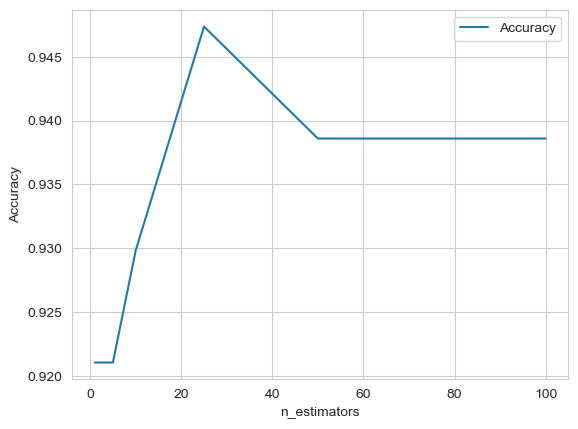

In [20]:
sns.lineplot(data = metrics_by_estimators, x="n_estimators", y="Accuracy", label="Accuracy")

### Questions

1. What happens as the number of estimators increases?
2. Does performance improve indefinitely?
3. At what point does performance appear to become relatively stable?
4. What is the trade-off between using more estimators and computational cost?

### Answers
1. The accuracy flattens out at 93.8%.
2. No
3. The performance flattens out at about 50 estimators.
4. The more estimators used, the more costly the computation.

# Task 11: Bagging with Different Base Models

Bagging can be used with different base estimators.

Your lecture demonstrated that `BaggingClassifier` can use models such as:

- Decision Trees
- Logistic Regression
- K-Nearest Neighbors

Build the following models.

### Bagged Decision Tree

In [21]:
various_models = []

bag_tree = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        random_state=42
    ),
    n_estimators=100,
    random_state=42
)

bag_tree.fit(
        X_train,
        y_train
    )

y_pred_tree = bag_tree.predict(
        X_test
    )

bag_tree_accuracy = accuracy_score(
        y_test,
        y_pred_tree
    )

bag_tree_f1 = f1_score(
        y_test,
        y_pred_tree
    )
various_models.append(["Bagged Decision Tree", bag_tree_accuracy, bag_tree_f1])

print("Accuracy:", bag_tree_accuracy)
print("F1:", bag_tree_f1)

Accuracy: 0.9385964912280702
F1: 0.9517241379310345


### Bagged Logistic Regression

In [22]:
bag_logistic = BaggingClassifier(
    estimator=LogisticRegression(
        max_iter=1000
    ),
    n_estimators=100,
    random_state=42
)

bag_logistic.fit(
        X_train,
        y_train
    )

y_pred_log = bag_logistic.predict(
        X_test
    )

log_accuracy = accuracy_score(
        y_test,
        y_pred_log
    )

log_f1 = f1_score(
        y_test,
        y_pred_log
    )
various_models.append(["Bagged Logistic Regression", log_accuracy, log_f1])

print("Accuracy:", log_accuracy)
print("F1:", log_f1)

c:\Users\jehow\anaconda3\envs\datascience\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\jehow\anaconda3\envs\datascience\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.

Accuracy: 0.956140350877193
F1: 0.9655172413793104


c:\Users\jehow\anaconda3\envs\datascience\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Bagged KNN

In [23]:
bag_knn = BaggingClassifier(
    estimator=KNeighborsClassifier(),
    n_estimators=100,
    random_state=42
)

bag_knn.fit(
        X_train,
        y_train
    )

y_pred_knn = bag_knn.predict(
        X_test
    )

knn_accuracy = accuracy_score(
        y_test,
        y_pred_knn
    )

knn_f1 = f1_score(
        y_test,
        y_pred_knn
    )
various_models.append(["Bagged KNN", knn_accuracy, knn_f1])

print("Accuracy:", knn_accuracy)
print("F1:", knn_f1)


Accuracy: 0.9122807017543859
F1: 0.9295774647887324


Train and evaluate all three.

Create a table:

| Model | Accuracy | F1 |
| --- | --- | --- |
| Bagged Decision Tree | ... | ... |
| Bagged Logistic Regression | ... | ... |
| Bagged KNN | ... | ... |

In [24]:
metrics_by_models = pd.DataFrame(various_models, columns=["Model", "Accuracy", "F1"])
metrics_by_models

,Model,Accuracy,F1
0,Bagged Decision Tree,0.938596,0.951724
1,Bagged Logistic Regression,0.956140,0.965517
2,Bagged KNN,0.912281,0.929577


### Questions

1. Which base model performed best with bagging?
2. Did bagging appear equally useful for all three models?
3. Which model benefited most from the ensemble?
4. Why might bagging be particularly useful for models with high variance?

### Answers
1. The Logistic Regression model perfomred the best with bagging.
2. No. It appeared especially useful for the Decision Tree.
3. The Decision Tree benefited the most from the ensemble as its accuracy went from 0.91 to 0.94.
4. Bagging reduces the variance of the model.

# Task 12: Build a Random Forest

Random Forest extends the bagging idea.

Create a Random Forest classifier:

In [25]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(
    X_train,
    y_train
)

y_pred_rf = rf.predict(
    X_test
)

rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

print("Accuracy:", rf_accuracy)
print("F1:", rf_f1)

Accuracy: 0.956140350877193
F1: 0.9655172413793104


# Task 13: Bagging vs. Random Forest

Create a comparison table:

| Model | Accuracy | F1 |
| --- | --- | --- |
| Decision Tree | ... | ... |
| Bagged Decision Trees | ... | ... |
| Random Forest | ... | ... |

In [26]:
Comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Bagged Decision Tree", "Random Forest"],
    "Accuracy": [tree_accuracy, bag_tree_accuracy, rf_accuracy],
    "F1 Score": [tree_f1, bag_tree_f1, rf_f1]
})
Comparison


,Model,Accuracy,F1 Score
0,Decision Tree,0.912281,0.928571
1,Bagged Decision Tree,0.938596,0.951724
2,Random Forest,0.956140,0.965517


### Questions

Explain:

1. What do Bagging and Random Forest have in common?
2. What additional randomness does Random Forest introduce?
3. How does random feature selection make the trees less correlated?
4. Which model performed best?
5. Why might reducing correlation between trees help the ensemble?

### Answers
1. Both Bagging and Random Forest randomize the data sets it trains on.
2. Random Forest also randomizes the features it trains on.
3. The trees are not trained on the same features, so they will not recognize the same patterns.
4. The Random Forest performed the best.
5. High correlation is more likely to overtrain the data.

### Key Concept

> **Random Forest = Bagged decision trees + random feature selection**

# Task 14: MDI Feature Importance

A Random Forest contains many decision trees.

Each tree makes predictions using splits based on features.

Scikit-learn provides feature importance through:

```
rf.feature_importances_
```

Create a pandas Series:

In [27]:
importance_mdi = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

print(importance_mdi)

# Check the total:

importance_mdi.sum()

worst area                 0.140016
worst concave points       0.129530
worst radius               0.097696
mean concave points        0.090885
worst perimeter            0.072226
mean perimeter             0.069574
mean radius                0.068676
mean concavity             0.057638
mean area                  0.049172
worst concavity            0.034340
area error                 0.033104
worst compactness          0.018600
worst texture              0.018597
radius error               0.016770
worst smoothness           0.012436
mean compactness           0.011715
perimeter error            0.009633
mean texture               0.009584
worst symmetry             0.008335
compactness error          0.005979
mean smoothness            0.005598
texture error              0.005214
worst fractal dimension    0.005166
mean symmetry              0.004666
mean fractal dimension     0.004489
fractal dimension error    0.004442
concavity error            0.004310
concave points error       0

1.0

### Questions

1. Which feature has the highest MDI importance?
2. Which three features are most important?
3. Which feature has the lowest importance?
4. What does a high MDI importance indicate?
5. What role do tree splits play in determining MDI importance?

### Answers
1. "worst area" has the highest MDI importance.
2. "Worst area", "worst concave points", "worst radius" are the three features that are the most important.
3. "smoothness error" has the lowest importance.
4. A high MDI importance indicates the feature is importance in the Random Forest.
5. The MDI is the measure of the decrease in impurity after the split.

# Task 15: Visualize MDI Feature Importance

Create a horizontal bar chart:

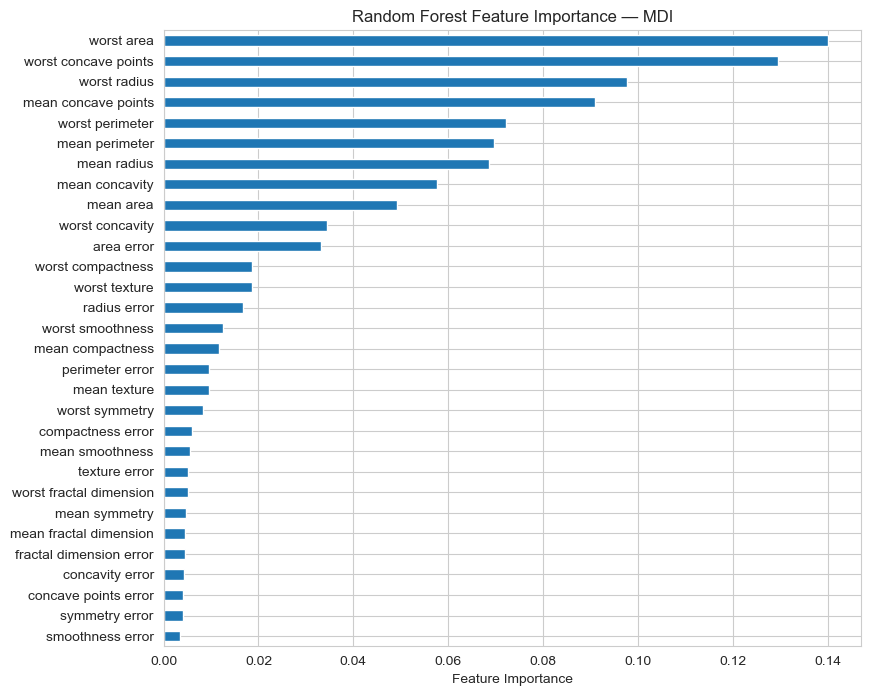

In [28]:
importance_mdi.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.xlabel(
    "Feature Importance"
)

plt.title(
    "Random Forest Feature Importance — MDI"
)

plt.show()

### Questions

Based on your visualization:

1. Which features does the model rely on most?
2. Are a few features responsible for a large proportion of the importance?
3. Are there features with very small importance values?
4. Does a low importance score necessarily mean the feature is useless?


### Answers
1. The worst area, concave points and radius are the most relied on.
2. Yes.
3. Yes.
4. No. The MDI is a comparison score, so it just means that one feature is less useful than another.

# Task 16: Interpret Feature Importance Carefully

Suppose your model reports:

```
worst radius → importance = 0.30
```

A student says:

> "Worst radius is the most important feature, so worst radius causes a tumor to be malignant."

### Question

Is this conclusion justified?

Explain why or why not.

Your answer should distinguish between:

- Predictive usefulness
- Association
- Causation

### Answer
This conclusion is not justified. The "worst radius" is the most predictively useful, but that does not imply causation. It only implies correlation.

### Key Principle

> **Feature importance tells us what the model found useful for prediction—not necessarily what causes the outcome.**

# Task 17: Permutation Importance

MDI is not the only way to measure feature importance.

Permutation importance asks:

> **What happens to model performance when we randomly shuffle a feature?**

Calculate permutation importance for the Random Forest:

In [29]:
result = permutation_importance(
    rf,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42
)

# Create a Series:

importance_permutation = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values(
    ascending=False
)

print(importance_permutation)


compactness error          7.894737e-03
mean concave points        7.894737e-03
worst texture              7.017544e-03
worst area                 7.017544e-03
mean area                  5.263158e-03
mean smoothness            5.263158e-03
radius error               4.385965e-03
mean radius                4.385965e-03
mean concavity             3.508772e-03
concave points error       3.508772e-03
worst smoothness           2.631579e-03
worst concave points       2.631579e-03
mean fractal dimension     1.754386e-03
mean symmetry              0.000000e+00
worst symmetry             0.000000e+00
worst concavity            0.000000e+00
worst compactness          0.000000e+00
mean perimeter             0.000000e+00
mean compactness           0.000000e+00
fractal dimension error    0.000000e+00
symmetry error             0.000000e+00
concavity error            0.000000e+00
mean texture               0.000000e+00
smoothness error           0.000000e+00
area error                 0.000000e+00


### Questions

1. Which feature has the highest permutation importance?
2. Which three features are most important?
3. Are the results identical to the MDI results?
4. Which features changed their ranking?
5. Are any features close to zero?

### Answers
1. Compactness Error had the highest permutation importance.
2. Compactness Error, Mean concave points, and worst texture were the three most important features.
3. No.
4. Almost all features changed in their ranking. None of the three most important features are duplicates.
5. Yes, there are many features close to zero.

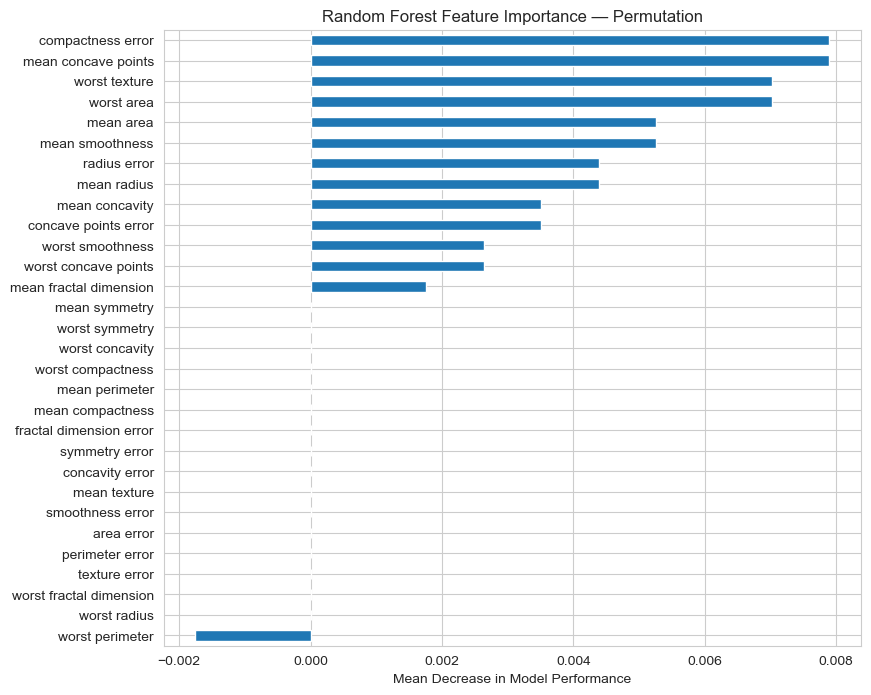

In [30]:
# Create a horizontal bar chart:

importance_permutation.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.xlabel(
    "Mean Decrease in Model Performance"
)

plt.title(
    "Random Forest Feature Importance — Permutation"
)

plt.show()

### Questions

1. Which features have the largest performance impact when shuffled?
2. Which features appear least important?
3. How does this visualization compare with the MDI visualization?

### Answers
1. Compactness error, mean concave points and worst texture have the largest performance impact when shuffled.
2. Worst perimeter appears to be the least important, as it actually improves the model when shuffled.
3. There are a lot more zeros in the Perumutation Importance graph.

# Task 19: Compare MDI and Permutation Importance

In [31]:
# Create a DataFrame comparing both methods:

importance_comparison = pd.DataFrame({
    "MDI": importance_mdi,
    "Permutation": importance_permutation
})

importance_comparison.sort_values(
    "MDI",
    ascending=False
)

,MDI,Permutation
worst area,0.140016,7.017544e-03
worst concave points,0.129530,2.631579e-03
worst radius,0.097696,-1.110223e-17
mean concave points,0.090885,7.894737e-03
worst perimeter,0.072226,-1.754386e-03
mean perimeter,0.069574,0.000000e+00
mean radius,0.068676,4.385965e-03
mean concavity,0.057638,3.508772e-03
mean area,0.049172,5.263158e-03
worst concavity,0.034340,0.000000e+00


### Complete the following table

| Question | Answer |
| --- | --- |
| MDI is based on... |Tree Splits|
| Permutation importance is based on... | Model Performance |
| MDI looks at... | Impurity Reduction |
| Permutation importance looks at... | Performance Decrease |
| One limitation of MDI is... | It does not handle correlated features well |
| One advantage of permutation importance is... | It handles features with many possible split points well |

### Analysis

Answer:

1. Which features are ranked highly by both methods?
2. Which features have different rankings?
3. Why might the two methods disagree?
4. Which method directly measures the effect of a feature on model performance?
5. Why might permutation importance take longer to calculate than MDI?

### Answers
1. Worst area, worst concave points, and mean concave points are all ranked highly in both methods.
2. Worst radius, worst perimeter, and mean perimeter are all ranked highly by MDI but not by Permutation Importance.
3. They might disagree because the try to minimize different things. Worst radius may do a great job of purifying a leaf node, however, it may actually purify it wrongly, leading to a low importance score.
4. Permutation Imporatnce.
5. Permutation Importance must recalculate the model for each shuffled feature.

# Task 20: Investigate Correlated Features

The lecture discussed an important limitation of feature importance: **correlated features**.

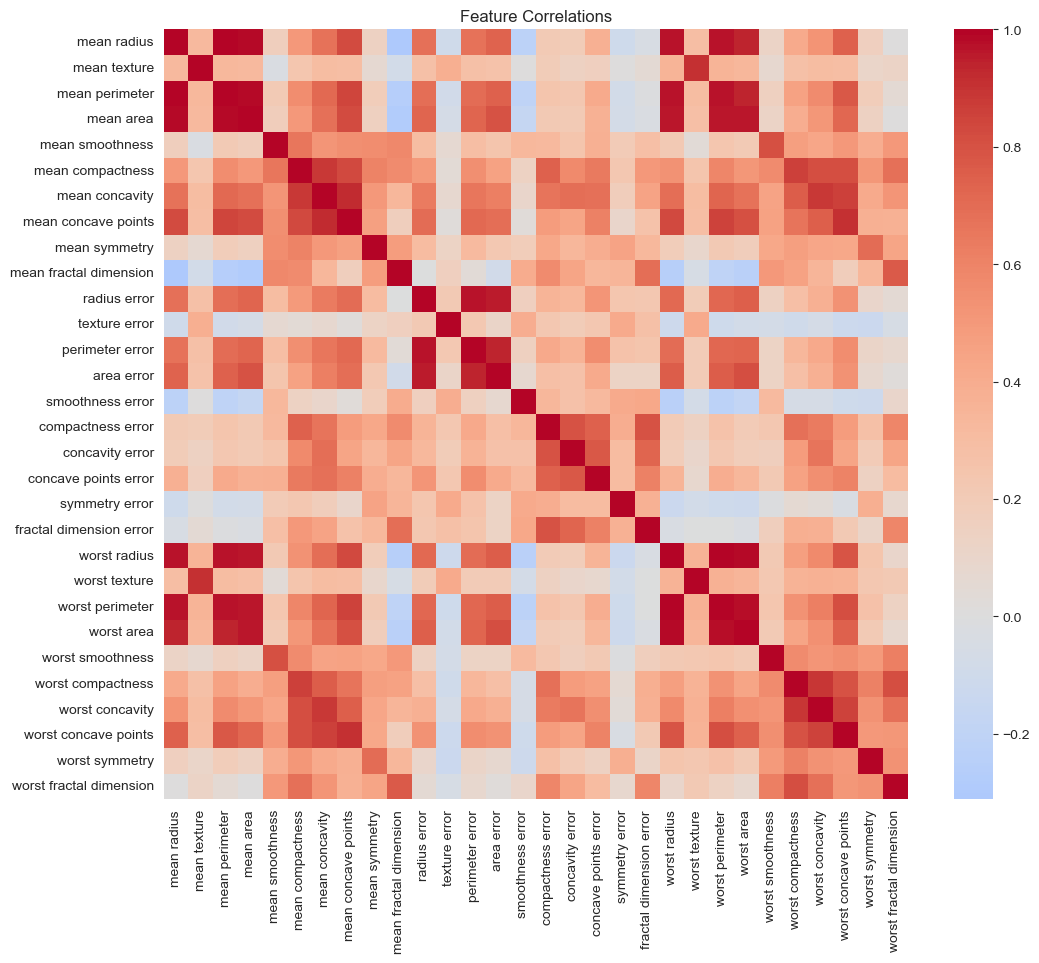

In [32]:
# <!-- Create a correlation matrix: -->

plt.figure(
    figsize=(12, 10)
)

sns.heatmap(
    X.corr(),
    cmap="coolwarm",
    center=0
)

plt.title(
    "Feature Correlations"
)

plt.show()

Worst Radius and Mean Radius are highly correlated.

### Questions

1. Which pair of features did you identify?
2. Why can correlated features make feature importance difficult to interpret?
3. If two features contain similar information, how might their importance be distributed?
4. Could a feature have low importance even though it contains useful information?
5. What does this tell you about interpreting feature importance?

### Answers
1. I identifyied worst radius and mean radius.
2. Correlated features end up splitting the importance in half.
3. THeir importance will be distributed accross the features.
4. Yes.
5. If we have many correlated features, we should pick one feature to train on.

# Task 21: Build a Voting Classifier

Your lecture also introduced `VotingClassifier`.

Build a voting classifier using:

- Decision Tree
- Logistic Regression
- KNN

```

In [33]:
voting_model = VotingClassifier(
    estimators=[
        (
            "tree",
            DecisionTreeClassifier(
                random_state=42
            )
        ),
        (
            "logistic",
            LogisticRegression(
                max_iter=1000
            )
        ),
        (
            "knn",
            KNeighborsClassifier()
        )
    ],
    voting="hard"
)


# Train the model:


voting_model.fit(
    X_train,
    y_train
)

# Generate predictions:

y_pred_voting = voting_model.predict(
    X_test
)

# Calculate accuracy and F1.
accuracy = accuracy_score(y_pred_voting, y_test)
f1 = f1_score(y_pred_voting, y_test)
print(accuracy, f1)


0.9473684210526315 0.9577464788732394


c:\Users\jehow\anaconda3\envs\datascience\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### Questions

1. How does hard voting make a prediction?
2. How is voting different from bagging?
3. Does the voting classifier outperform the individual models?
4. Why might combining different types of models be useful?

### Answers
1. Each model in the classifier votes on a class. The class with the most votes wins.
2. Voting uses different types of models, whereas uses different data sets.
3. No. Bagged Logistic Regression is stronger than the voting classifier.
4. Different models may pick up on different trends. Each individual models has its own strengths and weaknessess. The voting minimizes the weaknessess. 

# Task 22: Final Model Comparison

Create one final DataFrame containing the major models built throughout the lab.

Include:

- Decision Tree
- Bagged Decision Tree
- Bagged Logistic Regression
- Bagged KNN
- Random Forest
- Voting Classifier

The table should contain:

- Accuracy
- F1 score

For example:

| Model | Accuracy | F1 |
| --- | --- | --- |
| Decision Tree | ... | ... |
| Bagged Decision Tree | ... | ... |
| Bagged Logistic Regression | ... | ... |
| Bagged KNN | ... | ... |
| Random Forest | ... | ... |
| Voting Classifier | ... | ... |

Sort the table by F1 score from highest to lowest.

In [34]:
Final_df = pd.DataFrame({
    "Model": ["Decision Tree", "Bagged Decision Tree", "Bagged Logistic Regression", "Bagged KNN", "Random Forest", "Voting Classifier"],
    "Accuracy": [tree_accuracy, bag_tree_accuracy, log_accuracy, knn_accuracy, rf_accuracy, accuracy],
    "F1 Score": [tree_f1, bag_tree_f1, log_f1, knn_f1, rf_f1, f1]
})
Final_df

,Model,Accuracy,F1 Score
0,Decision Tree,0.912281,0.928571
1,Bagged Decision Tree,0.938596,0.951724
2,Bagged Logistic Regression,0.956140,0.965517
3,Bagged KNN,0.912281,0.929577
4,Random Forest,0.956140,0.965517
5,Voting Classifier,0.947368,0.957746


# Task 23: Final Analysis

Complete the following questions in a detailed Markdown cell.

## Bootstrapping

1. What is bootstrapping?
2. Why are observations repeated in a bootstrap sample?
3. Why might some observations be missing from a bootstrap sample?
4. Why does a bootstrap sample have the same number of observations as the original dataset?

### Answers
1. Bootstrapping is resampling the data in order to create new datasets from our data.
2. Observations are repeated because we allow for the same observation to be randomly selected multiple times.
3. We randomly select observations. This leads to some observations being left out.
4. We tell the bootstrap sample to have the same number of observations as the original dataset.

## Bagging

5. What does bagging stand for?
6. How does bagging use bootstrap samples?
7. How does bagging combine model predictions?
8. Why can bagging reduce variance?
9. Why is bagging particularly useful for high-variance models?

### Answers
5. Bagging is when we train an individual model on each of our bootstrapped samples.
6. Bagging trains an individual model on each of our bootstrapped samples.
7. If our data is categorical, the class with the most predictions is selected. If our data is numerical, the mean value is the prediction.
8. Bagging randomizes our data and helps prevent overfitting.
9. Bagging reduces the variance by randomizing the dataset helping to prevent overfitting.

## Random Forest

10. How does Random Forest extend bagging?
11. Why does Random Forest randomly select features?
12. Why is reducing the correlation between trees useful?
13. What is the difference between Bagging and Random Forest?

### Answers
10. Random Forest also selects random features.
11. Random feature selection makes the models less correlated.
12. Correlation of various features tends to increase the variance of the model.
13. Random Forest trains a model on a random selection of features, whereas bagging uses all the features.

## Feature Importance

14. What does MDI measure?
15. What does permutation importance measure?
16. Why might MDI and permutation importance produce different rankings?
17. Why can correlated features complicate feature importance?
18. Why does feature importance not imply causation?


### Answers
14. MDI measures the decrease in impurity of leaf nodes.
15. Permutation Imporatnce measures the decrease in performance of the model.
16. They measure different things. Purifying a leaf node may not necessarily improve model performance.
17. Feature importance is split over the correlated features, causing them to rank lower than they should be.
18. Things can be correlated without causing one another. Correlation is not causation.

## Model Selection

19. Which model performed best in your experiment?
20. How did the best ensemble compare with the single decision tree?
21. Did increasing the number of estimators always improve performance?
22. Which base model benefited most from bagging?
23. What are the advantages of using an ensemble?
24. What are the disadvantages?
25. If you were selecting a model for a real application, would you choose the model with the highest accuracy automatically? Explain.

### Answers
19. The Random Forest and Baggel Logistic Regression models performed equally well.
20. All the ensembles were better than the single decision tree.
21. No. We did find a point where adding estimators made no improvement.
22. The Logistic Regresssion model benefited the most from bagging. 
23. Ensembles decrease the variance of models.
24. Ensembles increase computing cost.
25. No. My goal may be to always be right when I think there is a true positive. In this case precision is more important than accuracy. My goal could also be to not miss any positives. In this case recall is more important than accuracy.